In [1]:
from optiland import optic, physical_apertures
import optiland.backend as be
from optiland.psf import MMDFTPSF
import matplotlib.pyplot as plt
import numpy as np
from scipy.special import j1
from scipy.special import jv
from scipy.stats import truncnorm
from scipy.optimize import differential_evolution
from poppy.zernike import zernike_basis
plt.rcParams['figure.figsize'] = (20,10)
from nautilus import Sampler
import corner
import pandas as pd
from optiland.wavefront import OPD
from matplotlib.colors import LogNorm

In [2]:
be.set_backend("numpy")
be.set_precision("float64")

In [3]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(np.ceil((-1 + np.sqrt(1 + 8 * j)) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(np.floor(n / 2.))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=128, rho=None, theta=None, outside=np.nan, zero=19.053609871416903, **kwargs):
 
    if theta is None and rho is None:
        x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = np.meshgrid(x, y)

        rho = np.sqrt(xx ** 2 + yy ** 2)
        theta = np.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not np.all(np.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = j1(2*np.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.cos(np.abs(m) * theta)
    else:
        cb_result = -1**(n/2 + np.abs(m)) * jv(n+1, 2*np.pi*rho) * (1/rho) * np.sin(np.abs(m) * theta)
    return cb_result


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in circbessel1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = np.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return basis_output

In [4]:
from functools import lru_cache

# --- drop-in helpers (uses your existing basis_vectors) ---

def _outside_key(outside):
    if outside is None or (isinstance(outside, float) and np.isnan(outside)):
        return "nan"
    return float(outside)

@lru_cache(maxsize=16)
def _polar_grid(npix, zero):
    x = (np.arange(npix, dtype=np.float64) - (npix - 1) / 2.0) / zero
    xx, yy = np.meshgrid(x, x)
    rho = np.sqrt(xx ** 2 + yy ** 2)
    theta = np.arctan2(yy, xx)
    return rho, theta

@lru_cache(maxsize=16)
def basis_vectors_cached(nterms=15, npix=256, zero=19.053609871416903, outside="nan"):
    """Cached wrapper around basis_vectors. `outside` must be hashable ('nan' or a float)."""
    outside_val = np.nan if outside == "nan" else float(outside)
    rho, theta = _polar_grid(npix, zero)
    return basis_vectors(
        nterms=nterms,
        rho=rho,
        theta=theta,
        outside=outside_val,
        zero=zero,
    )

def clear_basis_cache():
    basis_vectors_cached.cache_clear()
    _polar_grid.cache_clear()

def decompose_psf_cached(psf, nterms=15, outside=np.nan, **kwargs):
    npix = psf.shape[0]
    zero = kwargs.get("zero", 19.053609871416903)
    basis_stack = basis_vectors_cached(
        nterms=nterms,
        npix=npix,
        zero=zero,
        outside=_outside_key(outside),
    )
    basis_flat = basis_stack.reshape(nterms, -1)
    psf_flat = psf.ravel()
    numerators = basis_flat @ psf_flat
    denominators = np.einsum("ij,ij->i", basis_flat, basis_flat)
    return numerators / denominators

In [5]:
def decompose_psf(psf, nterms=10, basis=zernike_basis, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=0.0, **kwargs)
    basis_set = np.array(basis_set)
    basis_flat = basis_set.reshape(nterms, -1)
    numerators = basis_flat @ psf.ravel()
    denominators = np.einsum('ij,ij->i', basis_flat, basis_flat)
    coeffs = numerators / denominators
    return coeffs

In [6]:
def telescopeCreation(WL=0.65,pdx=0,pdy=0,pdz=0,ptx=0,pty=0,sdx=0,sdy=0,sdz=0,stx=0,sty=0):

    K=1000 #mm to micron
    #Pearl
    pearl = optic.Optic(name="Pearl")

    # set aperture
    pearl.set_aperture(aperture_type="EPD", value=6471.26)
    aperture1 = physical_apertures.RadialAperture(r_min=690, r_max=3210) 
    a1 = physical_apertures.PolygonAperture(x=[550, 3210, 3210, 550], y=[300, 300, -300, -300])
    a2 = physical_apertures.PolygonAperture(x=[-1835, -1375, 260, -260], y=[2705, 2955, 150, -150])
    a3 = physical_apertures.PolygonAperture(x=[-1835, -1375, 260, -260], y=[-2705, -2955, -150, 150])
    a = aperture1 - a1 - a2 - a3

    # set wavelengths
    pearl.wavelengths.add(value=WL)

    # add surfaces

    pearl.surfaces.add(
        index=0,
        radius=be.inf,
        thickness=be.inf,
    )

    # --- absolute mode from here: x, y, z (no thickness, no dx/dy) ---

    pearl.surfaces.add(
        index=1,
        radius=-16256,
        x=pdx / K,
        y=pdy / K,
        z=0 + pdz / K,              # independent M1 piston
        rx=np.deg2rad(ptx),
        ry=np.deg2rad(pty),
        conic=-0.995357,
        material="mirror",
        is_stop=True,
    )
    pearl.surfaces.add(
        index=2,
        radius=-1660.575,
        x=sdx / K,
        y=sdy / K,
        z=-7400.005 + sdz / K,              # independent M2 piston
        rx=np.deg2rad(stx),
        ry=np.deg2rad(sty),
        conic=-1.566503,
        material="mirror",
    )
    pearl.surfaces.add(
        index=3,
        radius=-1830.5174,
        x=0.0, y=0.0, z=49.965,          # M3 fixed in lab frame
        conic=-0.718069,
        material="mirror",
    )
    pearl.surfaces.add(
        index=4,
        radius=be.inf,
        x=0.0, y=0.0, z=-983.655,          # M4 fixed
        material="mirror",
    )
    pearl.surfaces.add(
        index=5,
        x=0.0, y=0.0, z=236.685,          # image / detector
    )
    pearl.fields.set_type(field_type="angle")
    pearl.fields.add(y=0.17)
    pearl.fields.add(y=0.285)
    pearl.fields.add(y=0.055)

    return pearl

In [7]:
def genpsf(WL=0.650, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field = (0,0)):

    telescope = telescopeCreation(WL, pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, num_rays=512)
    PSF = psf.psf[384:640,384:640]
    r = decompose_psf(PSF, nterms=dterms)

    return r

In [8]:
genpsf(dterms=15)

array([ 1.60429183e-01,  1.24316159e-03,  1.24316160e-03, -2.70885279e-01,
        1.11131075e-05, -8.64233347e-13, -3.44715589e-03, -3.44715586e-03,
        7.03609796e-07, -7.03612913e-07,  3.40720887e-01,  1.72374656e-12,
       -4.59393557e-05,  1.10417588e-05, -4.86729117e-14])

In [9]:
def genpsfn(WL=0.650, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5, field = (0,0)):

    telescope = telescopeCreation(WL, pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    psf = MMDFTPSF(telescope, field=field, wavelength=WL, num_rays=512)
    PSF = psf.psf[384:640,384:640]
    gauss_noise = np.random.normal(0, 0.01, PSF.shape)
    r = decompose_psf(PSF + gauss_noise, nterms=dterms)

    return r

In [40]:
xcy = []

for i in range(10000):
    px = np.round(np.random.normal(loc=0,scale=250), 2)
    py = np.round(np.random.normal(loc=0,scale=250), 2)
    pz = np.round(np.random.normal(loc=0,scale=50), 2)
    sx = np.round(np.random.normal(loc=0,scale=800), 2)
    sy = np.round(np.random.normal(loc=0,scale=800), 2)
    sz = np.round(np.random.normal(loc=0,scale=100), 2)
    ptx = np.round(np.random.normal(loc=0,scale=0.003), 2)
    pty = np.round(np.random.normal(loc=0,scale=0.003), 2)
    stx = np.round(np.random.normal(loc=0,scale=0.13), 2)
    sty = np.round(np.random.normal(loc=0,scale=0.13), 2)
    ars = genpsf(WL=0.65, pdx=px, pdy=py, pdz=pz, sdx=sx, sdy=sy, sdz=sz, ptx=ptx, pty=pty, stx=stx, sty=sty, dterms=11, field=(0.5,0.5))
    ars = np.array(ars.tolist()).T
    xcy.append(ars)

In [41]:
xcy = np.array(xcy)

In [42]:
np.cov(xcy.T)

array([[ 1.18100035e-04,  5.87284989e-06,  4.70300321e-06,
        -6.99806747e-05, -4.21112525e-07,  1.37980518e-06,
        -4.02915191e-06, -5.87508549e-06,  1.54360128e-07,
         8.05670981e-07,  3.71239597e-05],
       [ 5.87284989e-06,  8.22849679e-05, -2.09355502e-06,
        -2.35381631e-06,  3.22392493e-07,  3.21311377e-06,
         1.27966342e-06, -4.64328086e-05,  9.87260368e-07,
        -8.70377862e-07,  1.20766513e-06],
       [ 4.70300321e-06, -2.09355502e-06,  7.90916134e-05,
        -1.28327448e-06,  1.23350441e-06, -2.07007309e-06,
        -4.43130710e-05,  2.99323623e-06,  1.16492892e-06,
        -1.30774242e-07,  4.15804761e-07],
       [-6.99806747e-05, -2.35381631e-06, -1.28327448e-06,
         5.99819338e-05,  1.93930634e-06, -7.82860052e-07,
         3.01748343e-06,  3.25666868e-06,  1.01796046e-08,
        -3.97760949e-07, -3.89707411e-05],
       [-4.21112525e-07,  3.22392493e-07,  1.23350441e-06,
         1.93930634e-06,  2.10136544e-05,  2.28428926e-07,
  

In [10]:
#Truth

pdx_true = -152.75016400314658#truncnorm(-800, 800,loc=0,scale=250).rvs()
pdy_true =  316.9119521175452#truncnorm(-800, 800,loc=0,scale=250).rvs()
pdz_true =  26.63305492799793#truncnorm(-800, 800,loc=0,scale=50).rvs()
sdx_true =  -42.31026973120823#truncnorm(-2500, 2500,loc=0,scale=800).rvs()
sdy_true =  923.3301076415017#truncnorm(-2500, 2500,loc=0,scale=800).rvs()
sdz_true =  -32.7503419412196#truncnorm(-2500, 2500,loc=0,scale=100).rvs()
ptx_true =  2.9825886165449316e-05#truncnorm(-0.01, 0.01,loc=0,scale=0.003).rvs()
pty_true =  1.6083989287690292e-05#truncnorm(-0.01, 0.01,loc=0,scale=0.003).rvs()
stx_true =  0.02694973236912114#truncnorm(-0.4, 0.4,loc=0,scale=0.13).rvs()
sty_true =  0.009802980828159563#truncnorm(-0.4, 0.4,loc=0,scale=0.13).rvs()

## PSF
ct = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(0, 0.5965))
ctf10 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(1,0))
ctf01 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(0,1))
ctf11 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(1,1))
ctfm10 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(-1,0))
ctf0m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(0,-1))
ctfm11 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(-1,1))
ctf1m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(1,-1))
ctfm1m1 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(-1,-1))
ctf05 = genpsfn(WL=0.65, pdx=pdx_true, pdy=pdy_true, pdz=pdz_true, sdx=sdx_true, sdy=sdy_true, sdz=sdz_true, ptx=ptx_true, pty=pty_true, stx=stx_true, sty=sty_true, dterms=11, field=(0.5, 0.5))

print(f"{pdx_true},\n {pdy_true},\n {pdz_true},\n {sdx_true},\n {sdy_true}, \n {sdz_true}, \n {ptx_true},\n {pty_true},\n {stx_true},\n {sty_true}")

-152.75016400314658,
 316.9119521175452,
 26.63305492799793,
 -42.31026973120823,
 923.3301076415017, 
 -32.7503419412196, 
 2.9825886165449316e-05,
 1.6083989287690292e-05,
 0.02694973236912114,
 0.009802980828159563


In [14]:
from matplotlib_scalebar.scalebar import ScaleBar

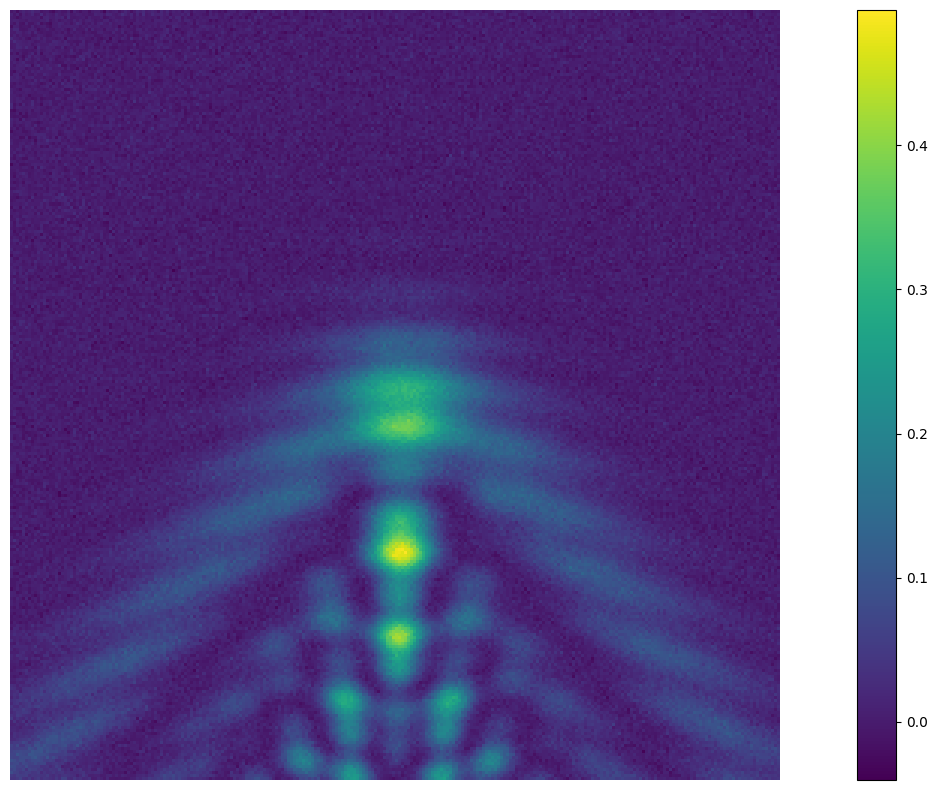

In [42]:
fig, ax = plt.subplots()
c = [pdx_true, pdy_true, pdz_true, sdx_true, sdy_true, sdz_true, ptx_true, pty_true, stx_true, sty_true]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=c[0], pdy=c[1], pdz=c[2], sdx=c[3], sdy=c[4], sdz=c[5], ptx=c[6], pty=c[7], stx=c[8], sty=c[9]), wavelength=0.65, field=(0,0.5965),num_rays=512).psf[384:640,384:640] + np.random.normal(0, 0.01, (256,256)))
#scalebar = ScaleBar(1.2054001730168418, "um", length_fraction=0.4, location="upper left", font_properties={"size": 64})
#ax.add_artist(scalebar)
plt.axis("off")
plt.colorbar()
plt.show()

In [11]:
C = np.array([[ 1.28916244e-04,  1.99210758e-06,  1.58193123e-06,
        -7.71978825e-05, -6.60891823e-09, -2.53444894e-06,
        -1.36833328e-06,  3.12996730e-07, -5.55185741e-08,
         1.18630467e-06,  4.34563850e-05],
       [ 1.99210758e-06,  8.93169842e-05,  2.52752078e-07,
         8.76151134e-07, -1.49742039e-07,  9.95880708e-07,
         1.77590621e-07, -5.09980727e-05, -2.76473197e-07,
        -5.03893644e-07, -5.69372195e-07],
       [ 1.58193123e-06,  2.52752078e-07,  8.47267419e-05,
         1.35902198e-06,  1.38945631e-06, -2.73515815e-08,
        -4.91630915e-05,  1.44968414e-06, -5.99962778e-07,
        -4.34892154e-07, -3.05454773e-06],
       [-7.71978825e-05,  8.76151134e-07,  1.35902198e-06,
         6.56374433e-05, -4.25039116e-07,  3.18904967e-07,
         1.01752943e-06, -1.06132357e-06, -3.18191155e-07,
        -2.80025943e-07, -4.35076722e-05],
       [-6.60891823e-09, -1.49742039e-07,  1.38945631e-06,
        -4.25039116e-07,  2.32274488e-05, -1.42600047e-07,
        -7.22716283e-07,  8.54065155e-08,  4.49354085e-07,
        -3.62987720e-07,  7.52025097e-07],
       [-2.53444894e-06,  9.95880708e-07, -2.73515815e-08,
         3.18904967e-07, -1.42600047e-07,  2.42438257e-05,
        -2.86159845e-07, -1.38803771e-06,  4.53513787e-07,
         4.17780825e-07,  2.45985706e-07],
       [-1.36833328e-06,  1.77590621e-07, -4.91630915e-05,
         1.01752943e-06, -7.22716283e-07, -2.86159845e-07,
         3.91856980e-05, -1.01804204e-06,  6.18151139e-07,
         2.85964911e-07,  1.15161832e-06],
       [ 3.12996730e-07, -5.09980727e-05,  1.44968414e-06,
        -1.06132357e-06,  8.54065155e-08, -1.38803771e-06,
        -1.01804204e-06,  3.71014053e-05,  2.23943226e-07,
         1.61678947e-07,  7.71242022e-07],
       [-5.55185741e-08, -2.76473197e-07, -5.99962778e-07,
        -3.18191155e-07,  4.49354085e-07,  4.53513787e-07,
         6.18151139e-07,  2.23943226e-07,  6.11445899e-06,
         3.95828571e-07,  5.66701616e-07],
       [ 1.18630467e-06, -5.03893644e-07, -4.34892154e-07,
        -2.80025943e-07, -3.62987720e-07,  4.17780825e-07,
         2.85964911e-07,  1.61678947e-07,  3.95828571e-07,
         5.80456500e-06, -2.26392288e-07],
       [ 4.34563850e-05, -5.69372195e-07, -3.05454773e-06,
        -4.35076722e-05,  7.52025097e-07,  2.45985706e-07,
         1.15161832e-06,  7.71242022e-07,  5.66701616e-07,
        -2.26392288e-07,  3.58071049e-05]])

Cf10 = np.array([[ 1.13833286e-04,  6.77972881e-07,  4.19858484e-06,
        -6.62420907e-05, -1.88012527e-08,  6.19470279e-06,
        -3.12332628e-06, -1.02756463e-06, -8.77941343e-08,
         2.45668180e-06,  3.40564851e-05],
       [ 6.77972881e-07,  7.53313029e-05, -1.22973721e-06,
         8.92007502e-07,  1.15228095e-06,  3.91947235e-06,
         1.00435856e-06, -3.84080361e-05, -2.78682408e-07,
         2.15046015e-06,  5.24929478e-07],
       [ 4.19858484e-06, -1.22973721e-06,  6.85938278e-05,
        -2.55807216e-06,  1.32958164e-06, -1.29381590e-06,
        -3.58545798e-05,  4.83892850e-07,  1.23130762e-06,
        -4.79915903e-08,  1.38300388e-06],
       [-6.62420907e-05,  8.92007502e-07, -2.55807216e-06,
         5.99301178e-05, -9.87908575e-08, -8.96126489e-07,
         2.36621381e-06,  1.46655041e-06,  5.19991838e-07,
        -7.49541799e-07, -3.78816334e-05],
       [-1.88012527e-08,  1.15228095e-06,  1.32958164e-06,
        -9.87908575e-08,  1.80073976e-05, -8.45234160e-07,
        -8.28787066e-07, -6.95092683e-07,  1.23453306e-06,
        -2.90488906e-07, -3.46488324e-07],
       [ 6.19470279e-06,  3.91947235e-06, -1.29381590e-06,
        -8.96126489e-07, -8.45234160e-07,  2.01154022e-05,
         4.26472968e-07, -2.04757579e-06,  1.60976656e-08,
         1.15528332e-06, -7.49255534e-07],
       [-3.12332628e-06,  1.00435856e-06, -3.58545798e-05,
         2.36621381e-06, -8.28787066e-07,  4.26472968e-07,
         2.73300657e-05, -1.11171843e-07, -7.02225844e-07,
         1.30735348e-08, -1.94421912e-06],
       [-1.02756463e-06, -3.84080361e-05,  4.83892850e-07,
         1.46655041e-06, -6.95092683e-07, -2.04757579e-06,
        -1.11171843e-07,  3.29160050e-05, -9.99954860e-08,
        -8.98940218e-07, -1.33104672e-06],
       [-8.77941343e-08, -2.78682408e-07,  1.23130762e-06,
         5.19991838e-07,  1.23453306e-06,  1.60976656e-08,
        -7.02225844e-07, -9.99954860e-08,  5.73248149e-06,
        -4.50062005e-08, -4.68493486e-07],
       [ 2.45668180e-06,  2.15046015e-06, -4.79915903e-08,
        -7.49541799e-07, -2.90488906e-07,  1.15528332e-06,
         1.30735348e-08, -8.98940218e-07, -4.50062005e-08,
         5.74529308e-06,  1.60424796e-07],
       [ 3.40564851e-05,  5.24929478e-07,  1.38300388e-06,
        -3.78816334e-05, -3.46488324e-07, -7.49255534e-07,
        -1.94421912e-06, -1.33104672e-06, -4.68493486e-07,
         1.60424796e-07,  3.19750219e-05]])

Cf01 = np.array([[ 1.21117885e-04, -4.85690632e-07, -2.78047973e-06,
        -7.09273737e-05,  2.20577813e-06, -2.07708495e-06,
        -2.04785296e-08, -2.95556040e-07, -8.32445765e-07,
         2.36966292e-06,  3.45043103e-05],
       [-4.85690632e-07,  7.29534457e-05, -1.18739683e-07,
        -9.10120061e-07,  6.21728104e-07,  1.34397222e-06,
        -3.02706789e-07, -3.79144699e-05, -1.02298130e-07,
        -8.85126425e-07,  1.01022461e-06],
       [-2.78047973e-06, -1.18739683e-07,  7.14256913e-05,
         2.40703438e-06, -1.37867984e-06, -1.52028883e-06,
        -3.74512037e-05,  8.15785655e-07, -2.36307609e-06,
         8.14283853e-08, -8.60218413e-07],
       [-7.09273737e-05, -9.10120061e-07,  2.40703438e-06,
         6.32262512e-05, -1.23382134e-06, -2.23477981e-06,
         7.50858566e-07,  5.17909630e-07, -2.33464943e-07,
        -1.55796052e-06, -3.86642346e-05],
       [ 2.20577813e-06,  6.21728104e-07, -1.37867984e-06,
        -1.23382134e-06,  1.79377919e-05, -8.52209706e-08,
         1.36606641e-06, -9.54871899e-08, -3.48030961e-07,
        -5.15470781e-07,  6.26872066e-07],
       [-2.07708495e-06,  1.34397222e-06, -1.52028883e-06,
        -2.23477981e-06, -8.52209706e-08,  1.88384423e-05,
         6.92069918e-07, -1.30377111e-06,  4.46359462e-07,
        -7.80724383e-08,  2.69800680e-06],
       [-2.04785296e-08, -3.02706789e-07, -3.74512037e-05,
         7.50858566e-07,  1.36606641e-06,  6.92069918e-07,
         3.42523367e-05,  1.85255634e-07,  1.20429412e-06,
        -1.79024396e-08, -8.14202045e-07],
       [-2.95556040e-07, -3.79144699e-05,  8.15785655e-07,
         5.17909630e-07, -9.54871899e-08, -1.30377111e-06,
         1.85255634e-07,  2.81154852e-05,  2.42477739e-07,
         3.68832094e-07, -7.43814810e-07],
       [-8.32445765e-07, -1.02298130e-07, -2.36307609e-06,
        -2.33464943e-07, -3.48030961e-07,  4.46359462e-07,
         1.20429412e-06,  2.42477739e-07,  5.76015665e-06,
        -1.99446737e-07,  5.00462571e-07],
       [ 2.36966292e-06, -8.85126425e-07,  8.14283853e-08,
        -1.55796052e-06, -5.15470781e-07, -7.80724383e-08,
        -1.79024396e-08,  3.68832094e-07, -1.99446737e-07,
         5.59414471e-06,  5.99766323e-07],
       [ 3.45043103e-05,  1.01022461e-06, -8.60218413e-07,
        -3.86642346e-05,  6.26872066e-07,  2.69800680e-06,
        -8.14202045e-07, -7.43814810e-07,  5.00462571e-07,
         5.99766323e-07,  3.22905936e-05]])

Cf11 = np.array([[ 1.07735510e-04,  4.83477101e-06,  3.94405867e-06,
        -5.87541979e-05,  1.37135888e-06, -8.43698103e-07,
        -2.05116866e-06, -3.79670526e-06,  5.74495647e-07,
        -7.33832704e-07,  2.59986420e-05],
       [ 4.83477101e-06,  5.56509888e-05,  3.69820194e-06,
        -3.90482169e-06,  1.69131408e-06,  1.67261273e-07,
        -1.29522183e-06, -2.48136801e-05,  1.81070144e-06,
        -1.76557852e-07,  2.81139245e-06],
       [ 3.94405867e-06,  3.69820194e-06,  5.54029074e-05,
        -4.34010496e-06,  2.61995809e-06, -1.14350491e-06,
        -2.58134827e-05, -1.45696339e-06,  7.09756907e-07,
        -1.62934004e-06,  4.11070688e-06],
       [-5.87541979e-05, -3.90482169e-06, -4.34010496e-06,
         5.28195402e-05,  2.81064892e-06, -1.41072184e-07,
         2.43457583e-06,  3.01464494e-06, -1.99778284e-07,
        -1.85005587e-07, -3.02222139e-05],
       [ 1.37135888e-06,  1.69131408e-06,  2.61995809e-06,
         2.81064892e-06,  1.50409135e-05, -4.32072142e-07,
        -9.43905779e-07, -7.45024391e-07, -7.61256955e-08,
        -3.33242270e-07, -1.99069738e-06],
       [-8.43698103e-07,  1.67261273e-07, -1.14350491e-06,
        -1.41072184e-07, -4.32072142e-07,  1.70666044e-05,
         2.68434560e-07, -8.56298248e-07,  5.70165555e-07,
         4.67534293e-07,  4.24758428e-07],
       [-2.05116866e-06, -1.29522183e-06, -2.58134827e-05,
         2.43457583e-06, -9.43905779e-07,  2.68434560e-07,
         2.26970328e-05,  2.45743463e-06, -1.21636493e-07,
         1.60364663e-07, -2.32421408e-06],
       [-3.79670526e-06, -2.48136801e-05, -1.45696339e-06,
         3.01464494e-06, -7.45024391e-07, -8.56298248e-07,
         2.45743463e-06,  2.09099624e-05, -4.94647245e-07,
        -2.70104008e-07, -2.46729436e-06],
       [ 5.74495647e-07,  1.81070144e-06,  7.09756907e-07,
        -1.99778284e-07, -7.61256955e-08,  5.70165555e-07,
        -1.21636493e-07, -4.94647245e-07,  5.99176133e-06,
        -9.44751180e-08,  1.07244974e-07],
       [-7.33832704e-07, -1.76557852e-07, -1.62934004e-06,
        -1.85005587e-07, -3.33242270e-07,  4.67534293e-07,
         1.60364663e-07, -2.70104008e-07, -9.44751180e-08,
         6.51702111e-06,  1.82430014e-07],
       [ 2.59986420e-05,  2.81139245e-06,  4.11070688e-06,
        -3.02222139e-05, -1.99069738e-06,  4.24758428e-07,
        -2.32421408e-06, -2.46729436e-06,  1.07244974e-07,
         1.82430014e-07,  2.55422259e-05]])

Cfm10 = np.array([[ 1.20886605e-04, -6.68569140e-07,  5.76906326e-06,
        -7.30831393e-05, -6.70914656e-07,  1.87411807e-06,
        -4.97952314e-06,  1.75557945e-06,  8.09949354e-07,
         1.64507219e-07,  3.82814477e-05],
       [-6.68569140e-07,  7.09638957e-05, -4.47187962e-07,
         1.12900811e-06,  2.11263344e-06, -8.54837018e-07,
        -6.07352673e-08, -3.65441282e-05, -1.55781730e-07,
         2.16142955e-06, -1.87212496e-06],
       [ 5.76906326e-06, -4.47187962e-07,  7.48831751e-05,
        -4.46677255e-06, -1.74099900e-06, -1.90903281e-06,
        -3.91098501e-05, -7.94154473e-07,  5.45248526e-07,
         1.19239083e-06,  1.63094012e-06],
       [-7.30831393e-05,  1.12900811e-06, -4.46677255e-06,
         6.60859649e-05, -5.33098824e-08,  1.70567575e-06,
         3.52468058e-06, -2.32836995e-06, -3.22657303e-07,
        -7.35026659e-07, -4.23282636e-05],
       [-6.70914656e-07,  2.11263344e-06, -1.74099900e-06,
        -5.33098824e-08,  1.81023039e-05,  7.32128986e-07,
         1.04790377e-06, -1.29703947e-06, -2.01313174e-07,
        -1.06959342e-08,  1.76011630e-07],
       [ 1.87411807e-06, -8.54837018e-07, -1.90903281e-06,
         1.70567575e-06,  7.32128986e-07,  1.99418338e-05,
         1.43746865e-06,  2.14450965e-07,  1.10004717e-06,
        -5.17290473e-07, -2.44590876e-06],
       [-4.97952314e-06, -6.07352673e-08, -3.91098501e-05,
         3.52468058e-06,  1.04790377e-06,  1.43746865e-06,
         2.89098990e-05,  4.11175760e-07, -2.59509424e-07,
        -7.47787516e-07, -9.95583181e-07],
       [ 1.75557945e-06, -3.65441282e-05, -7.94154473e-07,
        -2.32836995e-06, -1.29703947e-06,  2.14450965e-07,
         4.11175760e-07,  3.24241657e-05,  1.91724202e-07,
        -9.45405508e-07,  1.32314457e-06],
       [ 8.09949354e-07, -1.55781730e-07,  5.45248526e-07,
        -3.22657303e-07, -2.01313174e-07,  1.10004717e-06,
        -2.59509424e-07,  1.91724202e-07,  5.75687898e-06,
        -9.58904373e-08, -1.73968414e-07],
       [ 1.64507219e-07,  2.16142955e-06,  1.19239083e-06,
        -7.35026659e-07, -1.06959342e-08, -5.17290473e-07,
        -7.47787516e-07, -9.45405508e-07, -9.58904373e-08,
         5.84107682e-06,  4.66647601e-07],
       [ 3.82814477e-05, -1.87212496e-06,  1.63094012e-06,
        -4.23282636e-05,  1.76011630e-07, -2.44590876e-06,
        -9.95583181e-07,  1.32314457e-06, -1.73968414e-07,
         4.66647601e-07,  3.58574489e-05]])

Cf0m1 = np.array([[ 1.20532488e-04,  2.89580139e-06,  5.65697422e-07,
        -6.94907489e-05, -2.12915100e-06, -4.71617722e-06,
         4.94500211e-07, -2.13349162e-06, -1.81425807e-07,
         4.87625641e-07,  3.40609461e-05],
       [ 2.89580139e-06,  6.98950400e-05, -1.53624494e-06,
        -1.46481674e-06, -1.20867994e-08,  1.04856685e-06,
         1.02101485e-06, -3.61967002e-05, -5.98292197e-07,
        -1.50115187e-07,  8.02768621e-07],
       [ 5.65697422e-07, -1.53624494e-06,  7.61957842e-05,
        -1.09112261e-06,  3.41943236e-07,  4.89650215e-07,
        -3.93695566e-05, -4.01868951e-07, -2.75187554e-06,
        -2.19285304e-07,  7.19875981e-07],
       [-6.94907489e-05, -1.46481674e-06, -1.09112261e-06,
         6.09187691e-05,  1.43941282e-06, -8.40510551e-07,
         5.54597953e-08,  1.32319821e-06,  4.01880502e-07,
        -1.10419111e-07, -3.73258386e-05],
       [-2.12915100e-06, -1.20867994e-08,  3.41943236e-07,
         1.43941282e-06,  1.82265609e-05,  3.17418585e-07,
        -3.83863929e-07,  5.75811452e-08, -2.68218333e-07,
         7.19883226e-07, -5.09833865e-07],
       [-4.71617722e-06,  1.04856685e-06,  4.89650215e-07,
        -8.40510551e-07,  3.17418585e-07,  2.12922700e-05,
         3.44318814e-08, -3.53304239e-07, -6.21811952e-07,
         4.17737270e-07,  1.98216422e-06],
       [ 4.94500211e-07,  1.02101485e-06, -3.93695566e-05,
         5.54597953e-08, -3.83863929e-07,  3.44318814e-08,
         3.36829849e-05, -1.45012691e-07,  1.54918664e-06,
         3.65718601e-07, -9.02415266e-07],
       [-2.13349162e-06, -3.61967002e-05, -4.01868951e-07,
         1.32319821e-06,  5.75811452e-08, -3.53304239e-07,
        -1.45012691e-07,  2.80201201e-05,  5.43220834e-07,
         2.38987703e-07, -7.38809807e-07],
       [-1.81425807e-07, -5.98292197e-07, -2.75187554e-06,
         4.01880502e-07, -2.68218333e-07, -6.21811952e-07,
         1.54918664e-06,  5.43220834e-07,  6.64861094e-06,
        -1.43813278e-07, -1.99619292e-09],
       [ 4.87625641e-07, -1.50115187e-07, -2.19285304e-07,
        -1.10419111e-07,  7.19883226e-07,  4.17737270e-07,
         3.65718601e-07,  2.38987703e-07, -1.43813278e-07,
         6.12556909e-06,  1.91109177e-07],
       [ 3.40609461e-05,  8.02768621e-07,  7.19875981e-07,
        -3.73258386e-05, -5.09833865e-07,  1.98216422e-06,
        -9.02415266e-07, -7.38809807e-07, -1.99619292e-09,
         1.91109177e-07,  3.15278254e-05]])

Cfm11 = np.array([[ 1.09648012e-04, -1.21212429e-06,  1.11277785e-06,
        -5.59639429e-05, -2.88305182e-06,  4.70353481e-07,
        -7.10940471e-07, -8.15916509e-07, -1.17957952e-06,
        -4.09513448e-07,  2.41217198e-05],
       [-1.21212429e-06,  5.95847460e-05, -3.74853197e-06,
         2.26648176e-06,  1.39379661e-06,  3.48495342e-07,
         1.34173641e-06, -2.73659341e-05, -2.02129672e-06,
        -1.44242273e-06, -2.33476785e-06],
       [ 1.11277785e-06, -3.74853197e-06,  5.54913688e-05,
        -2.02752054e-06, -1.50137480e-06, -1.17176936e-06,
        -2.42854549e-05,  1.07960915e-06,  1.62587466e-06,
         1.33426093e-06,  1.70956648e-06],
       [-5.59639429e-05,  2.26648176e-06, -2.02752054e-06,
         4.97698010e-05, -2.69370711e-06, -6.17957297e-07,
        -1.14654162e-07,  1.91439870e-07,  5.30889655e-07,
        -1.51020820e-07, -2.82785779e-05],
       [-2.88305182e-06,  1.39379661e-06, -1.50137480e-06,
        -2.69370711e-06,  1.76759913e-05, -2.64930335e-07,
         8.72553808e-07, -6.12787518e-07, -3.06575113e-07,
        -5.82373415e-07,  2.70924386e-06],
       [ 4.70353481e-07,  3.48495342e-07, -1.17176936e-06,
        -6.17957297e-07, -2.64930335e-07,  1.54124029e-05,
         8.12879601e-07, -4.43246000e-07,  1.85144854e-07,
        -4.77928222e-08,  8.77802864e-07],
       [-7.10940471e-07,  1.34173641e-06, -2.42854549e-05,
        -1.14654162e-07,  8.72553808e-07,  8.12879601e-07,
         2.03639302e-05, -2.52762076e-06, -4.44948222e-07,
        -5.62572742e-07, -1.71366177e-07],
       [-8.15916509e-07, -2.73659341e-05,  1.07960915e-06,
         1.91439870e-07, -6.12787518e-07, -4.43246000e-07,
        -2.52762076e-06,  2.31568267e-05,  5.10467012e-07,
         8.90367016e-07,  5.40594345e-07],
       [-1.17957952e-06, -2.02129672e-06,  1.62587466e-06,
         5.30889655e-07, -3.06575113e-07,  1.85144854e-07,
        -4.44948222e-07,  5.10467012e-07,  6.31438104e-06,
         4.41086915e-07, -9.23451858e-08],
       [-4.09513448e-07, -1.44242273e-06,  1.33426093e-06,
        -1.51020820e-07, -5.82373415e-07, -4.77928222e-08,
        -5.62572742e-07,  8.90367016e-07,  4.41086915e-07,
         6.51355236e-06,  2.47374793e-07],
       [ 2.41217198e-05, -2.33476785e-06,  1.70956648e-06,
        -2.82785779e-05,  2.70924386e-06,  8.77802864e-07,
        -1.71366177e-07,  5.40594345e-07, -9.23451858e-08,
         2.47374793e-07,  2.40957883e-05]])

Cf1m1 = np.array([[ 1.03648624e-04,  1.23363412e-06, -3.23275488e-06,
        -5.91033290e-05, -3.74410855e-06,  3.01640361e-06,
         9.24939845e-07,  1.29769071e-07,  1.26694413e-07,
         4.43888703e-07,  2.91323510e-05],
       [ 1.23363412e-06,  5.74495562e-05, -5.07874109e-06,
        -2.37331584e-06, -3.12981499e-06,  5.05594708e-07,
         2.35867400e-06, -2.55587394e-05, -2.19009748e-06,
        -7.01633227e-07,  3.06881692e-06],
       [-3.23275488e-06, -5.07874109e-06,  5.44152210e-05,
         3.41183835e-06,  2.31343557e-06,  5.64859807e-07,
        -2.46107155e-05,  2.76876648e-06,  1.51054071e-06,
         1.43148711e-06, -3.84839919e-06],
       [-5.91033290e-05, -2.37331584e-06,  3.41183835e-06,
         5.55969478e-05, -1.14050540e-06, -2.58347545e-06,
        -1.62735200e-06,  2.30425335e-07, -5.93863218e-07,
        -3.14499002e-07, -3.30843483e-05],
       [-3.74410855e-06, -3.12981499e-06,  2.31343557e-06,
        -1.14050540e-06,  1.57585526e-05, -1.15683006e-07,
        -1.50180607e-06,  1.62421048e-06, -8.84603209e-08,
         3.05060544e-07,  1.40843024e-06],
       [ 3.01640361e-06,  5.05594708e-07,  5.64859807e-07,
        -2.58347545e-06, -1.15683006e-07,  1.54215488e-05,
        -4.54352027e-07, -7.50402076e-07, -3.47955641e-07,
         3.68763916e-07,  1.77266177e-06],
       [ 9.24939845e-07,  2.35867400e-06, -2.46107155e-05,
        -1.62735200e-06, -1.50180607e-06, -4.54352027e-07,
         2.22285770e-05, -3.08451048e-06, -5.55831031e-07,
        -5.25590164e-07,  2.56955699e-06],
       [ 1.29769071e-07, -2.55587394e-05,  2.76876648e-06,
         2.30425335e-07,  1.62421048e-06, -7.50402076e-07,
        -3.08451048e-06,  2.07798298e-05,  7.11931185e-07,
         9.42185307e-09, -1.34099482e-06],
       [ 1.26694413e-07, -2.19009748e-06,  1.51054071e-06,
        -5.93863218e-07, -8.84603209e-08, -3.47955641e-07,
        -5.55831031e-07,  7.11931185e-07,  5.73981678e-06,
         1.46564735e-07,  1.88494580e-07],
       [ 4.43888703e-07, -7.01633227e-07,  1.43148711e-06,
        -3.14499002e-07,  3.05060544e-07,  3.68763916e-07,
        -5.25590164e-07,  9.42185307e-09,  1.46564735e-07,
         5.58944856e-06, -1.76013350e-07],
       [ 2.91323510e-05,  3.06881692e-06, -3.84839919e-06,
        -3.30843483e-05,  1.40843024e-06,  1.77266177e-06,
         2.56955699e-06, -1.34099482e-06,  1.88494580e-07,
        -1.76013350e-07,  2.70299771e-05]])

Cfm1m1 = np.array([[ 1.03135965e-04, -4.72486457e-06, -3.78680821e-06,
        -5.47378173e-05,  4.90895147e-06,  1.80436599e-06,
        -1.02326526e-06,  2.25415415e-06, -1.65706353e-07,
        -1.74823015e-06,  2.33508348e-05],
       [-4.72486457e-06,  5.55435338e-05,  2.17676171e-06,
         4.79230326e-06, -1.83603393e-06, -1.93648938e-06,
         6.12800823e-09, -2.57125500e-05,  2.68831236e-06,
        -3.87703938e-07, -3.54579748e-06],
       [-3.78680821e-06,  2.17676171e-06,  5.19989220e-05,
         4.20630799e-06, -2.03703115e-06, -1.26286076e-07,
        -2.27806135e-05, -1.20467031e-06,  1.59040843e-06,
        -2.02982059e-06, -4.45405339e-06],
       [-5.47378173e-05,  4.79230326e-06,  4.20630799e-06,
         4.93801374e-05,  6.00870483e-07, -6.61249575e-07,
         4.43141893e-07, -1.66577685e-06,  8.18660535e-08,
         1.20009154e-06, -2.75532063e-05],
       [ 4.90895147e-06, -1.83603393e-06, -2.03703115e-06,
         6.00870483e-07,  1.57811162e-05,  4.82801489e-08,
         5.85931413e-07,  7.52976904e-07, -1.50587613e-07,
         7.13924437e-08, -9.89251316e-07],
       [ 1.80436599e-06, -1.93648938e-06, -1.26286076e-07,
        -6.61249575e-07,  4.82801489e-08,  1.52399405e-05,
         2.82206344e-07,  1.97250903e-06, -2.80494558e-07,
        -2.17508741e-08,  7.97851688e-07],
       [-1.02326526e-06,  6.12800823e-09, -2.27806135e-05,
         4.43141893e-07,  5.85931413e-07,  2.82206344e-07,
         2.02998747e-05,  2.48181149e-06, -7.42942946e-07,
         8.33058718e-07,  1.57305176e-06],
       [ 2.25415415e-06, -2.57125500e-05, -1.20467031e-06,
        -1.66577685e-06,  7.52976904e-07,  1.97250903e-06,
         2.48181149e-06,  2.21212465e-05, -8.16347153e-07,
         5.94276392e-08,  1.69451874e-06],
       [-1.65706353e-07,  2.68831236e-06,  1.59040843e-06,
         8.18660535e-08, -1.50587613e-07, -2.80494558e-07,
        -7.42942946e-07, -8.16347153e-07,  5.41858596e-06,
         4.84595059e-08, -1.57868178e-07],
       [-1.74823015e-06, -3.87703938e-07, -2.02982059e-06,
         1.20009154e-06,  7.13924437e-08, -2.17508741e-08,
         8.33058718e-07,  5.94276392e-08,  4.84595059e-08,
         5.77258083e-06, -4.02890263e-07],
       [ 2.33508348e-05, -3.54579748e-06, -4.45405339e-06,
        -2.75532063e-05, -9.89251316e-07,  7.97851688e-07,
         1.57305176e-06,  1.69451874e-06, -1.57868178e-07,
        -4.02890263e-07,  2.36380510e-05]])

Cf05 = np.array([[ 1.18100035e-04,  5.87284989e-06,  4.70300321e-06,
        -6.99806747e-05, -4.21112525e-07,  1.37980518e-06,
        -4.02915191e-06, -5.87508549e-06,  1.54360128e-07,
         8.05670981e-07,  3.71239597e-05],
       [ 5.87284989e-06,  8.22849679e-05, -2.09355502e-06,
        -2.35381631e-06,  3.22392493e-07,  3.21311377e-06,
         1.27966342e-06, -4.64328086e-05,  9.87260368e-07,
        -8.70377862e-07,  1.20766513e-06],
       [ 4.70300321e-06, -2.09355502e-06,  7.90916134e-05,
        -1.28327448e-06,  1.23350441e-06, -2.07007309e-06,
        -4.43130710e-05,  2.99323623e-06,  1.16492892e-06,
        -1.30774242e-07,  4.15804761e-07],
       [-6.99806747e-05, -2.35381631e-06, -1.28327448e-06,
         5.99819338e-05,  1.93930634e-06, -7.82860052e-07,
         3.01748343e-06,  3.25666868e-06,  1.01796046e-08,
        -3.97760949e-07, -3.89707411e-05],
       [-4.21112525e-07,  3.22392493e-07,  1.23350441e-06,
         1.93930634e-06,  2.10136544e-05,  2.28428926e-07,
        -1.02147919e-06, -6.03474122e-07,  3.73783817e-07,
        -8.38453596e-07, -1.77463318e-06],
       [ 1.37980518e-06,  3.21311377e-06, -2.07007309e-06,
        -7.82860052e-07,  2.28428926e-07,  2.06607623e-05,
         1.55602261e-06, -1.61024061e-06,  4.80130081e-07,
         1.06099970e-06,  8.26326141e-07],
       [-4.02915191e-06,  1.27966342e-06, -4.43130710e-05,
         3.01748343e-06, -1.02147919e-06,  1.55602261e-06,
         3.43241300e-05, -2.96155943e-07, -7.58449116e-07,
         1.03231372e-07, -1.40879330e-06],
       [-5.87508549e-06, -4.64328086e-05,  2.99323623e-06,
         3.25666868e-06, -6.03474122e-07, -1.61024061e-06,
        -2.96155943e-07,  3.58441330e-05, -5.51971633e-07,
         4.43127695e-07, -1.14986033e-06],
       [ 1.54360128e-07,  9.87260368e-07,  1.16492892e-06,
         1.01796046e-08,  3.73783817e-07,  4.80130081e-07,
        -7.58449116e-07, -5.51971633e-07,  5.39699155e-06,
        -4.38818096e-08, -2.88751620e-07],
       [ 8.05670981e-07, -8.70377862e-07, -1.30774242e-07,
        -3.97760949e-07, -8.38453596e-07,  1.06099970e-06,
         1.03231372e-07,  4.43127695e-07, -4.38818096e-08,
         5.47927273e-06,  2.62464441e-07],
       [ 3.71239597e-05,  1.20766513e-06,  4.15804761e-07,
        -3.89707411e-05, -1.77463318e-06,  8.26326141e-07,
        -1.40879330e-06, -1.14986033e-06, -2.88751620e-07,
         2.62464441e-07,  3.28478244e-05]])


Cinv =    np.linalg.inv(C)  # precision matrix
Cf10inv = np.linalg.inv(Cf10)
Cf01inv = np.linalg.inv(Cf01)
Cf11inv = np.linalg.inv(Cf11)
Cfm10inv = np.linalg.inv(Cfm10)
Cf0m1inv = np.linalg.inv(Cf0m1)
Cfm11inv = np.linalg.inv(Cfm11)
Cf1m1inv = np.linalg.inv(Cf1m1)
Cfm1m1inv = np.linalg.inv(Cfm1m1)
Cf05inv = np.linalg.inv(Cf05)
lnorm =    -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(C)))  # ln(normalization)
lnormf10 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf10))) 
lnormf01 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf01))) 
lnormf11 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf11))) 
lnormfm10 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cfm10))) 
lnormf0m1 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf0m1))) 
lnormfm11 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cfm11)))
lnormf1m1 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf1m1)))
lnormfm1m1 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cfm1m1)))
lnormf05 = -0.5 * (np.log(2*np.pi) * 10 + np.log(np.linalg.det(Cf05)))

# log-likelihood
def loglike(theta):
    lpdx,lpdy,lpdz,lsdx,lsdy,lsdz,lptx,lpty,lstx,lsty = theta
    ## PSF
    c = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11 , field=(0, 0.5965))
    cf10 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(1,0))
    cf01 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(0,1))
    cf11 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(1,1))
    cfm10 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(-1,0))
    cf0m1 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(0,-1))
    cfm11 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(-1,1))
    cf1m1 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(1,-1))
    cfm1m1 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(-1,-1))
    cf05 = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, pdz=lpdz, sdx=lsdx, sdy=lsdy, sdz=lsdz, ptx=lptx, pty=lpty, stx=lstx, sty=lsty, dterms=11, field=(0.5,0.5))
    
    return -0.5 * np.matmul(c-ct, np.matmul(Cinv, c-ct)) + lnorm -0.5 * np.matmul(cf10-ctf10, np.matmul(Cf10inv, cf10-ctf10)) + lnormf10 -0.5 * np.matmul(cf01-ctf01, np.matmul(Cf01inv, cf01-ctf01)) + lnormf01 -0.5 * np.matmul(cf11-ctf11, np.matmul(Cf11inv, cf11-ctf11)) + lnormf11 -0.5 * np.matmul(cfm10-ctfm10, np.matmul(Cfm10inv, cfm10-ctfm10)) + lnormfm10 -0.5 * np.matmul(cf0m1-ctf0m1, np.matmul(Cf0m1inv, cf0m1-ctf0m1)) + lnormf0m1 -0.5 * np.matmul(cfm11-ctfm11, np.matmul(Cfm11inv, cfm11-ctfm11)) + lnormfm11 -0.5 * np.matmul(cf1m1-ctf1m1, np.matmul(Cf1m1inv, cf1m1-ctf1m1)) + lnormf1m1 -0.5 * np.matmul(cfm1m1-ctfm1m1, np.matmul(Cfm1m1inv, cfm1m1-ctfm1m1)) + lnormfm1m1 -0.5 * np.matmul(cf05-ctf05, np.matmul(Cf05inv, cf05-ctf05)) + lnormf05

# prior transform
def ptform(utheta):

    upx,upy,upz,usx,usy,usz,uptx,upty,ustx,usty = utheta

    xpx =  800. * (2. * upx - 1.)
    xpy =  800. * (2. * upy - 1.)
    xpz =  800. * (2. * upz - 1.)
    xsx =  2500. * (2. * usx - 1.)
    xsy =  2500. * (2. * usy - 1.)
    xsz =  2500. * (2. * usz - 1.)
    tpx =  0.01 * (2. * uptx - 1.)
    tpy =  0.01 * (2. * upty - 1.)
    tsx =  0.4 * (2. * ustx - 1.)
    tsy =  0.4 * (2. * usty - 1.)

    return xpx,xpy,xpz,xsx,xsy,xsz,tpx,tpy,tsx,tsy

In [12]:
loglike([pdx_true, pdy_true, pdz_true, sdx_true, sdy_true, sdz_true, ptx_true, pty_true, stx_true, sty_true])

np.float64(508.24291628733806)

In [13]:
lnorm + lnormf10 + lnormf01 + lnormf11 + lnormfm10 + lnormf0m1 + lnormfm11 + lnormf1m1 + lnormfm1m1 + lnormf05

np.float64(508.2563940348749)

In [14]:
print([pdx_true, pdy_true, pdz_true, sdx_true, sdy_true, sdz_true, ptx_true, pty_true, stx_true, sty_true])

[-152.75016400314658, 316.9119521175452, 26.63305492799793, -42.31026973120823, 923.3301076415017, -32.7503419412196, 2.9825886165449316e-05, 1.6083989287690292e-05, 0.02694973236912114, 0.009802980828159563]


In [47]:
sampler = Sampler(ptform, loglike, n_dim=10)
sampler.run(verbose=True)

Starting the nautilus sampler...
Please report issues at github.com/johannesulf/nautilus.
Status    | Bounds | Ellipses | Networks | Calls    | f_live | N_eff | log Z    
Finished  | 38     | 1        | 4        | 93200    | N/A    | 20373 | +484.69  


np.True_

In [71]:
points, log_w, log_l = sampler.posterior()
figure = corner.corner(
    points, weights=np.exp(log_w), labels=['Pdx', 'Pdy', 'Pdz', 'Sdx', 'Sdy', 'Sdz', 'Ptx', 'Pty', 'Stx', 'Sty'],
    quantiles=[0.16, 0.5, 0.84],
    show_titles=True,)

NameError: name 'sampler' is not defined

In [49]:
x0 = [(np.quantile(points[-100:,0], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,1], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,2], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,3], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,4], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,5], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,6], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,7], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,8], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'),
      np.quantile(points[-100:,9], 0.5, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]

In [50]:
print(x0)

[(array(-156.08514143), array(329.45839292), array(59.52159352), array(-52.88489196), array(852.9971309), array(1.25561018), array(-0.00026229), array(0.00082091), array(0.0257526), array(0.00998523))]


In [51]:
print(f"{pdx_true},\n {pdy_true}, \n {pdz_true},\n {sdx_true},\n {sdy_true}, \n {sdz_true}, \n {ptx_true},\n {pty_true},\n {stx_true},\n {sty_true}")

-152.75016400314658,
 316.9119521175452, 
 26.63305492799793,
 -42.31026973120823,
 923.3301076415017, 
 -32.7503419412196, 
 2.9825886165449316e-05,
 1.6083989287690292e-05,
 0.02694973236912114,
 0.009802980828159563


In [52]:
bounds = [(np.quantile(points[-100:,0], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,0], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,1], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'),np.quantile(points[-100:,1], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,2], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,2], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,3], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,3], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,4], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,4], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,5], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,5], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,6], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,6], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,7], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,7], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,8], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,8], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf')), (np.quantile(points[-100:,9], 0.021, weights=np.exp(log_w)[-100:], method='inverted_cdf'), np.quantile(points[-100:,9], 0.979, weights=np.exp(log_w)[-100:], method='inverted_cdf'))]

In [17]:
bounds

[(-711.01454326, 634.62883661),
 (-320.14994557, 760.93448734),
 (-131.74872611, 341.54114045),
 (-1510.14805135, 1569.58463458),
 (-522.39560624, 2387.03873492),
 (-187.49604503, 277.52959379),
 (-0.00894239, 0.00924757),
 (-0.00987663, 0.00883954),
 (0.00714548, 0.03869936),
 (0.00106751, 0.02105905)]

In [28]:
bounds = [(-800, 800), (-800, 800), (-800, 800), (-2500, 2500), (-2500, 2500), (-2500, 2500), (-0.01, 0.01), (-0.01, 0.01), (-0.4, 0.4), (-0.4, 0.4)]

In [ ]:
bounds = [(-711.01454326, 634.62883661),
          (-320.14994557, 760.93448734),
          (-131.74872611, 341.54114045),
          (-1510.14805135, 1569.58463458),
          (-522.39560624, 2387.03873492),
          (-187.49604503, 277.52959379),
          (-0.00894239, 0.00924757),
          (-0.00987663, 0.00883954),
          (0.00714548, 0.03869936),
          (0.00106751, 0.02105905)]

In [16]:
x0 = [-156.08514143, 329.45839292, 59.52159352, -52.88489196, 852.9971309, 1.25561018, -0.00026229, 0.00082091, 0.0257526, 0.00998523]

In [ ]:
def my_callback(intermediate_result):
    # intermediate_result is an OptimizeResult object
    with open("solutions_logtma.txt", "a") as f:
        f.write(f"Objective: {intermediate_result.fun}, Best X: {intermediate_result.x}\n")
    if intermediate_result.fun <= 1e-15:
        print(f"Terminating: reached objective value {intermediate_result.fun}")
        return True  # Returns True to halt optimization
    return False

In [21]:
def lstep(t):
      return np.sum(np.array(ct - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(0, 0.5965)))**2 + np.array(ctf10 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(1,0)))**2 + np.array(ctf01 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(0,1)))**2 + np.array(ctf11 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(1,1)))**2 + np.array(ctfm10 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(-1,0)))**2 + np.array(ctf0m1 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(0,-1)))**2 + np.array(ctfm11 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(-1,1)))**2 + np.array(ctf1m1 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(1,-1)))**2 + np.array(ctfm1m1 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(-1,-1)))**2 + np.array(ctf05 - genpsf(WL=0.65, pdx=t[0], pdy=t[1], pdz=t[2], sdx=t[3], sdy=t[4], sdz=t[5], ptx=t[6], pty=t[7], stx=t[8], sty=t[9], dterms=11, field=(0.5,0.5)))**2)
result = differential_evolution(lstep, bounds, callback = my_callback, x0=x0, tol=1e-10, disp=True)
print(pdx_true, pdy_true, pdz_true, sdx_true, sdy_true, sdz_true, ptx_true, pty_true, stx_true, sty_true)
print(result.x)

differential_evolution step 1: f(x)= 0.0003556071247454809
differential_evolution step 2: f(x)= 0.0003556071247454809


KeyboardInterrupt: 

In [24]:
c = [-1.55302418e+02, 3.27148036e+02, 3.02582448e+01, 3.81307381e+00, 9.32856898e+02, -2.92185235e+01, 6.71487167e-06, -3.49563957e-04, 2.67581581e-02, 9.52334256e-03]

pdx_true-c[0], pdy_true-c[1], pdz_true-c[2], sdx_true-c[3], sdy_true-c[4], sdz_true-c[5], ptx_true-c[6], pty_true-c[7], stx_true-c[8], sty_true-c[9]

(2.552253996853409,
 -10.236083882454807,
 -3.625189872002071,
 -46.12334354120823,
 -9.52679035849826,
 -3.5318184412196025,
 2.3111014495449318e-05,
 0.00036564794628769033,
 0.00019157426912114195,
 0.0002796382681595627)

np.float64(8.240067820733454)

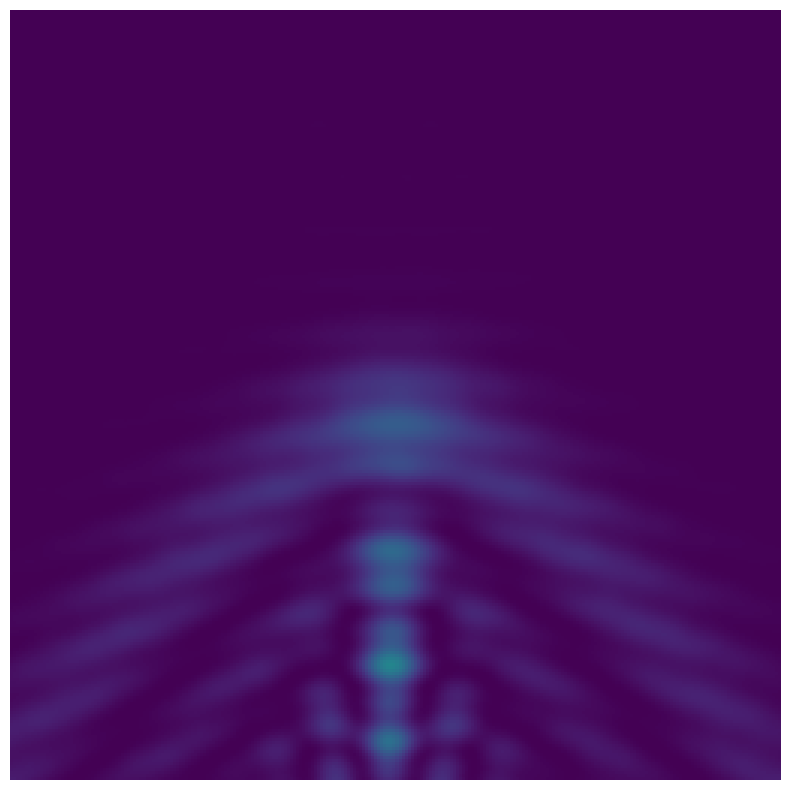

In [55]:
c = [0,0,0,0,0,0,0,0,0,0]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=1)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.007334407101242235)

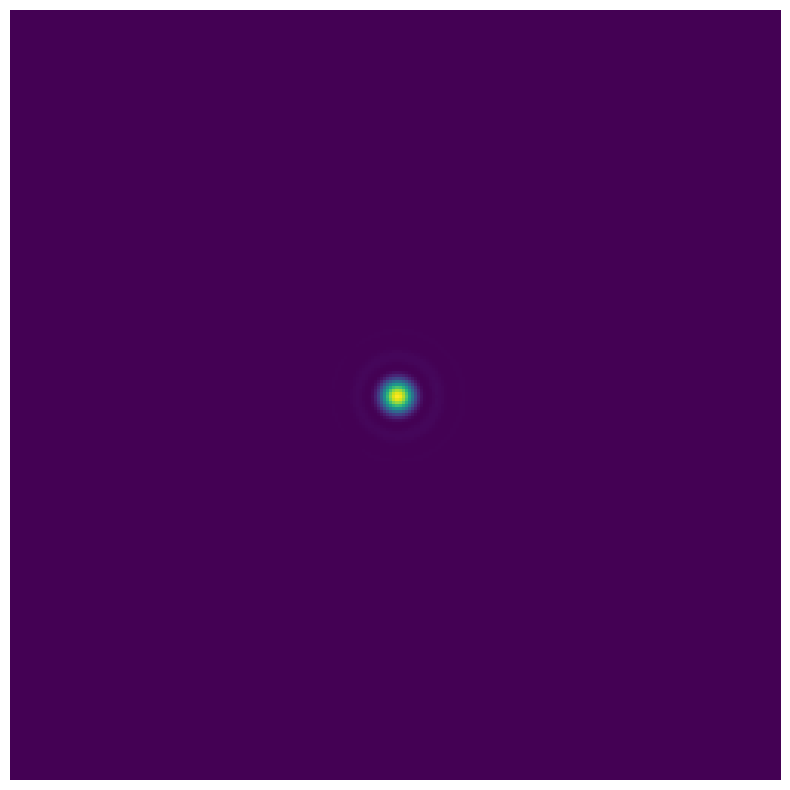

In [56]:
c = [-1.59439863e+02, 3.09977862e+02, 2.47687054e+01, -3.80105860e+01,
      9.39845144e+02, -3.45597370e+01, 2.22398098e-04, -6.80066107e-05,
      2.72674290e-02, 9.79098655e-03]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640])
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.9912494318493896)

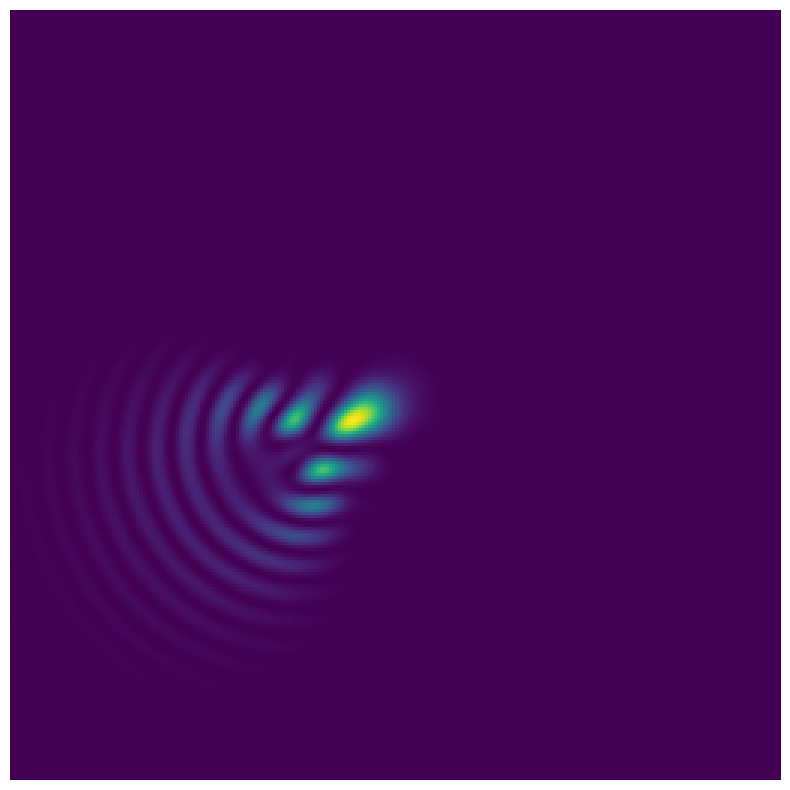

In [57]:
c = [-156.08514143, 329.45839292, 59.52159352, -52.88489196, 852.9971309, 1.25561018, -0.00026229, 0.00082091, 0.0257526, 0.00998523]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640])
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.01952438591813456)

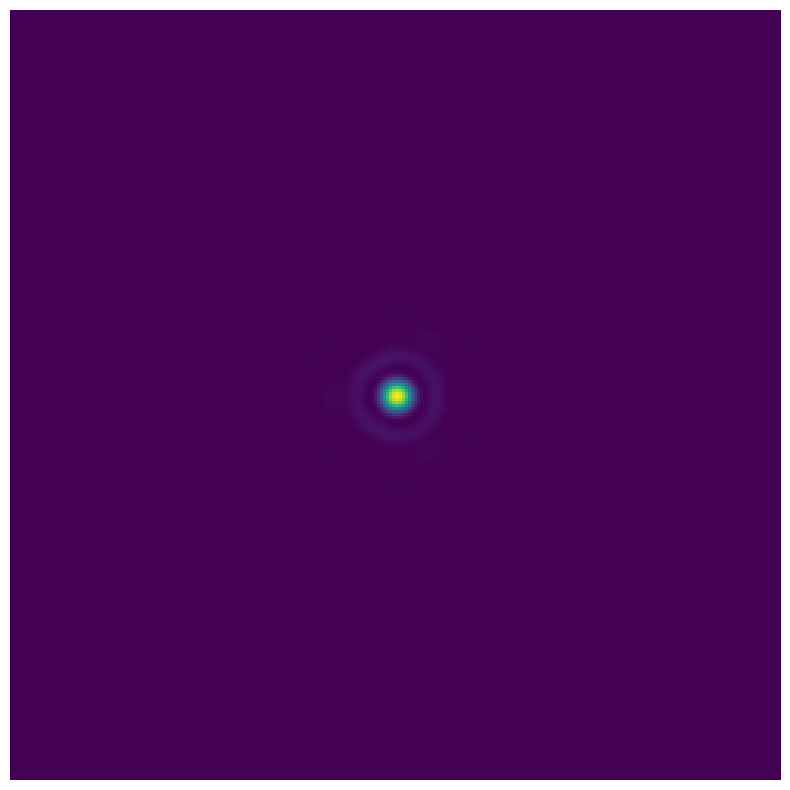

In [ ]:
c = [-1.58181603e+02, 3.45045009e+02, 2.07581736e+01, -3.00501339e+01, 9.64194321e+02, -4.07223508e+02, 5.74179377e-03, -5.94095927e-03, 3.15801833e-02, 2.92844168e-02]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640])
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(38.26573575014829)

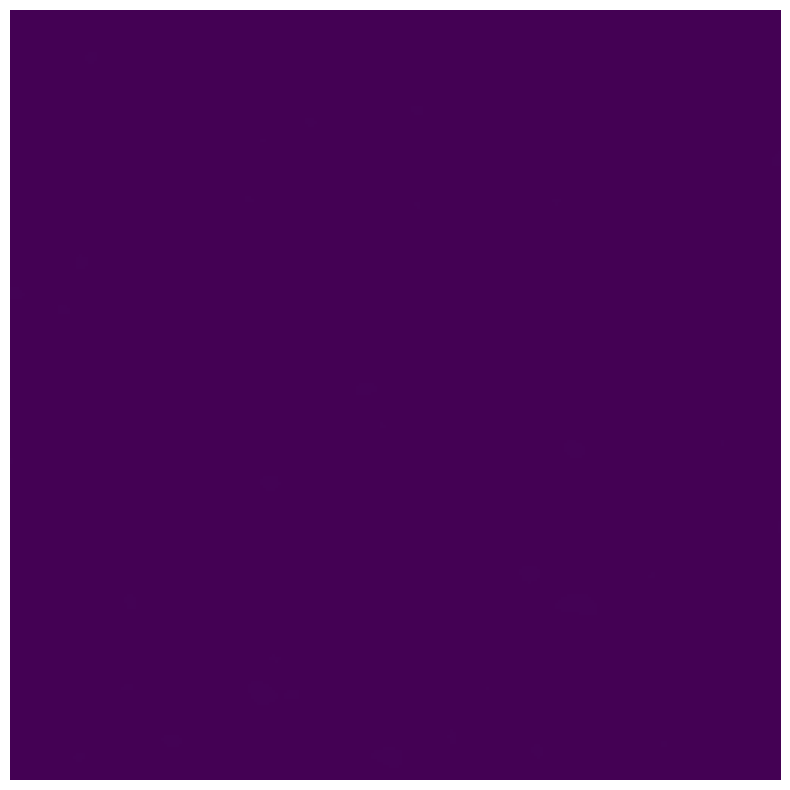

In [31]:
c = [ 7.99133911e+02, -7.99763356e+02, -7.99842769e+02, -2.49976419e+03,
  2.49682590e+03,  2.49686405e+03,  7.55811579e-03, -8.17533002e-03,
 -3.44534315e-01, -3.98128664e-01]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.03954899404266935)

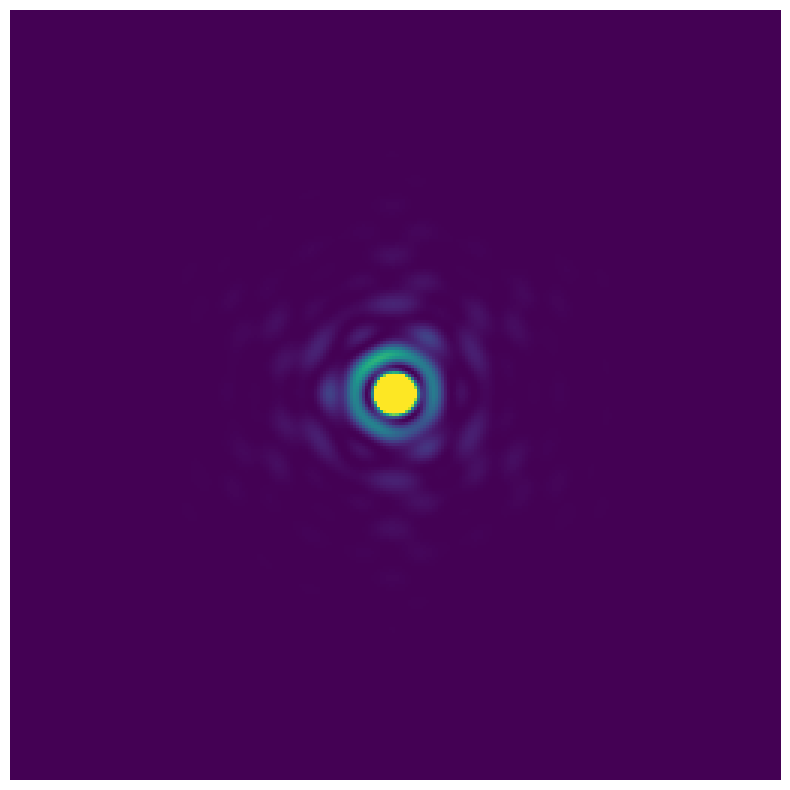

In [ ]:
c = [2.70710077e+02, -5.83261193e+01, 3.57215215e+01, 3.39955365e+02, 6.08760313e+02, 5.95178251e+02, 5.45239242e-03, 3.97565703e-03, -1.84966817e-01, -1.59490807e-01]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.021084170578274136)

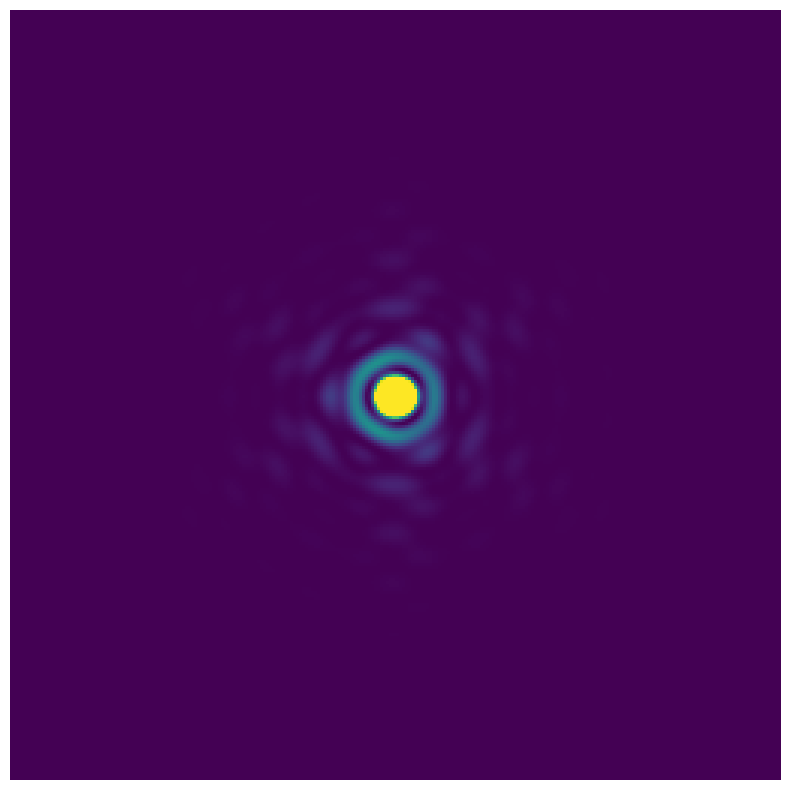

In [ ]:
c = [-9.60982819e+01, -1.67262156e+01, 5.48195323e+01, 5.40854177e-02, 6.18159521e+02, 1.79845845e+03, 7.97418699e-03, 7.87416783e-03, -2.77159865e-02, 1.66755747e-02]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.0014528809851290473)

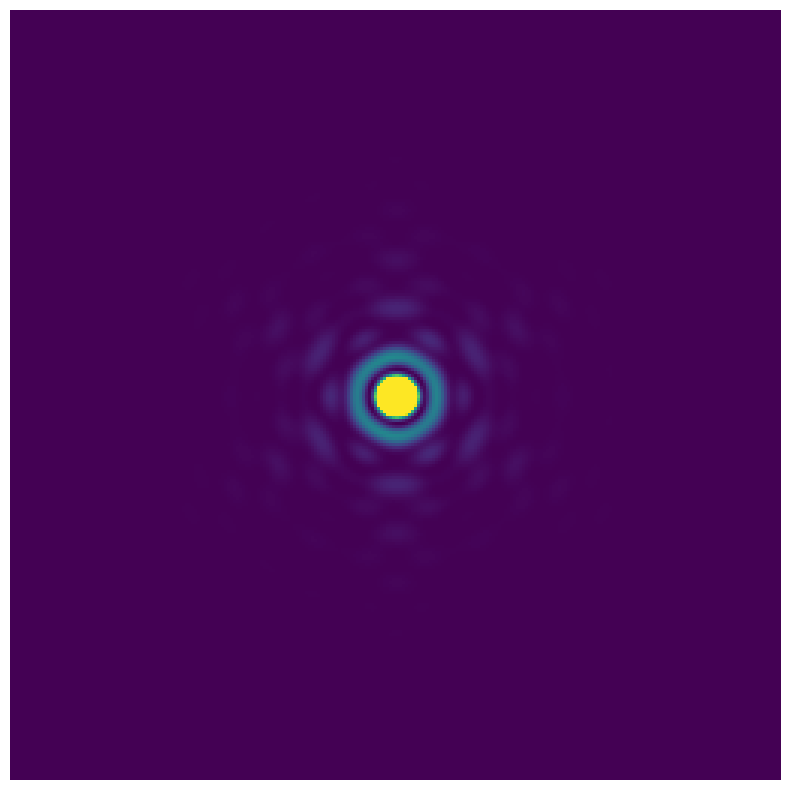

In [ ]:
c = [-1.53485600e+02, 3.02265820e+02, 2.47802756e+01, -6.30275771e+01, 9.04780936e+02, -1.53262262e+02, -2.84360586e-03, 9.26637345e-03, 1.50037278e-02, 1.43177187e-02]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

np.float64(0.0013799176788977425)

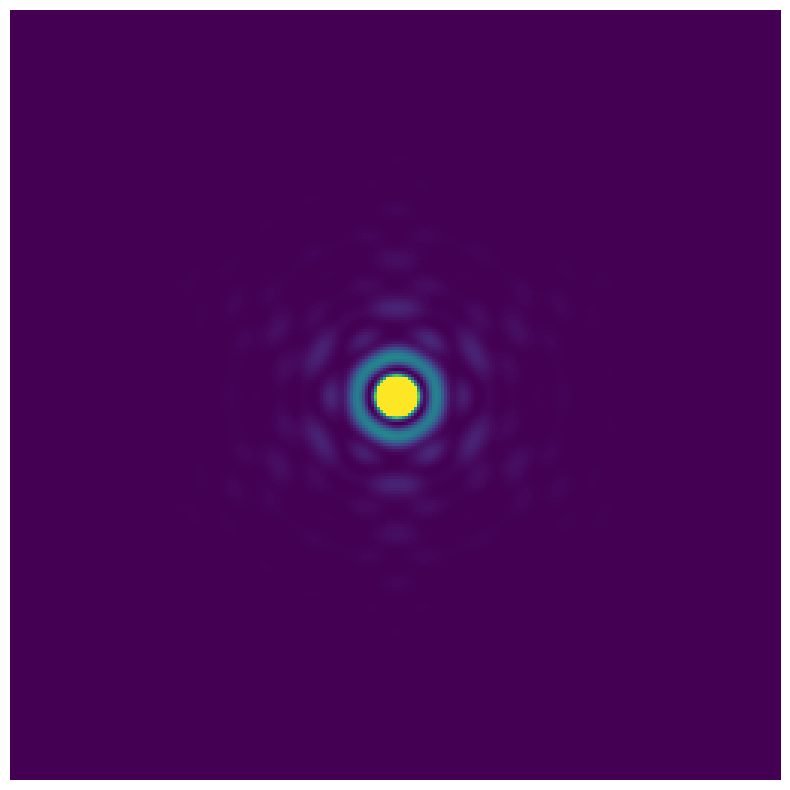

In [ ]:
c = [-1.54857144e+02, 3.05542159e+02, 2.43779043e+01, -6.45113602e+01, 9.06428999e+02, -1.79067257e+02, -2.64823506e-03, 9.99261984e-03, 2.44098564e-02, 2.15194286e-02]
plt.imshow(MMDFTPSF(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), wavelength=0.65, field=(0,0), num_rays=512).psf[384:640,384:640], vmax=10)
plt.axis('off')

np.nanstd(OPD(telescopeCreation(), field=(0, 0), wavelength=0.65).generate_opd_map()['z']-OPD(telescopeCreation(pdx=pdx_true-c[0], pdy=pdy_true-c[1], pdz=pdz_true-c[2], sdx=sdx_true-c[3], sdy=sdy_true-c[4], sdz=sdz_true-c[5], ptx=ptx_true-c[6], pty=pty_true-c[7], stx=stx_true-c[8], sty=sty_true-c[9]), field=(0, 0), wavelength=0.65).generate_opd_map()['z'])

In [ ]:
import sys
print(sys.version)

3.11.4 (main, Jul  5 2023, 08:40:20) [Clang 14.0.6 ]


In [ ]:
pdx_true-c[0], pdy_true-c[1], pdz_true-c[2], sdx_true-c[3], sdy_true-c[4], sdz_true-c[5], ptx_true-c[6], pty_true-c[7], stx_true-c[8], sty_true-c[9]

(np.float64(0.7354359968534254),
 np.float64(14.646132117545164),
 np.float64(1.8527793279979292),
 np.float64(20.717307368791772),
 np.float64(18.549171641501744),
 np.float64(120.51192005878039),
 np.float64(0.0028734317461654494),
 np.float64(-0.00925028946071231),
 np.float64(0.01194600456912114),
 np.float64(-0.004514737871840438))

In [ ]:
pdx_true-c[0], pdy_true-c[1], pdz_true-c[2], sdx_true-c[3], sdy_true-c[4], sdz_true-c[5], ptx_true-c[6], pty_true-c[7], stx_true-c[8], sty_true-c[9]

(2.1069799968534255,
 11.369793117545157,
 2.255150627997928,
 22.20109046879177,
 16.901108641501764,
 146.3169150587804,
 0.0026780609461654493,
 -0.00997653585071231,
 0.0025398759691211414,
 -0.011716447771840438)

In [ ]:
import pandas as pd

In [ ]:
import io

with open('solutions_logp.txt', 'r') as f:
    lines = f.read().splitlines()

# Join every three lines together with a comma
processed_data = []
for i in range(0, len(lines), 3):
    processed_data.append(" ".join(lines[i:i+3]))

In [ ]:
output_string = "\n".join(processed_data)

with open('cleaned_data.txt', 'w') as f:
    f.write(output_string)

In [ ]:
df = pd.read_csv('cleaned_data.txt', header=None, sep=r'\s+', on_bad_lines='skip')

In [ ]:
df

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
0,Objective:,"0.0007660020689049385,",Best,X:,[,-59.480614,54.702086,25.358309,87.904983,658.388055,-120.662358,0.000957,-0.001028,-0.017614,-4.24540622e-02]
1,Objective:,"0.0007660020689049385,",Best,X:,[,-59.480614,54.702086,25.358309,87.904983,658.388055,-120.662358,0.000957,-0.001028,-0.017614,-4.24540622e-02]
2,Objective:,"0.0007660020689049385,",Best,X:,[,-59.480614,54.702086,25.358309,87.904983,658.388055,-120.662358,0.000957,-0.001028,-0.017614,-4.24540622e-02]
3,Objective:,"0.0007660020689049385,",Best,X:,[,-59.480614,54.702086,25.358309,87.904983,658.388055,-120.662358,0.000957,-0.001028,-0.017614,-4.24540622e-02]
4,Objective:,"0.0005348000827842976,",Best,X:,[,-394.937774,-1.265393,25.072832,-288.241144,597.546442,-684.793733,0.000630,-0.001573,0.011290,-8.05919563e-02]
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,Objective:,"2.530293393843023e-07,",Best,X:,[,-153.485600,302.265820,24.780276,-63.027577,904.780936,-153.262262,-0.002844,0.009266,0.015004,1.43177187e-02]
996,Objective:,"2.530293393843023e-07,",Best,X:,[,-153.485600,302.265820,24.780276,-63.027577,904.780936,-153.262262,-0.002844,0.009266,0.015004,1.43177187e-02]
997,Objective:,"2.530293393843023e-07,",Best,X:,[,-153.485600,302.265820,24.780276,-63.027577,904.780936,-153.262262,-0.002844,0.009266,0.015004,1.43177187e-02]
998,Objective:,"2.530293393843023e-07,",Best,X:,[,-153.485600,302.265820,24.780276,-63.027577,904.780936,-153.262262,-0.002844,0.009266,0.015004,1.43177187e-02]


Text(0, 0.5, 'Pdx Value')

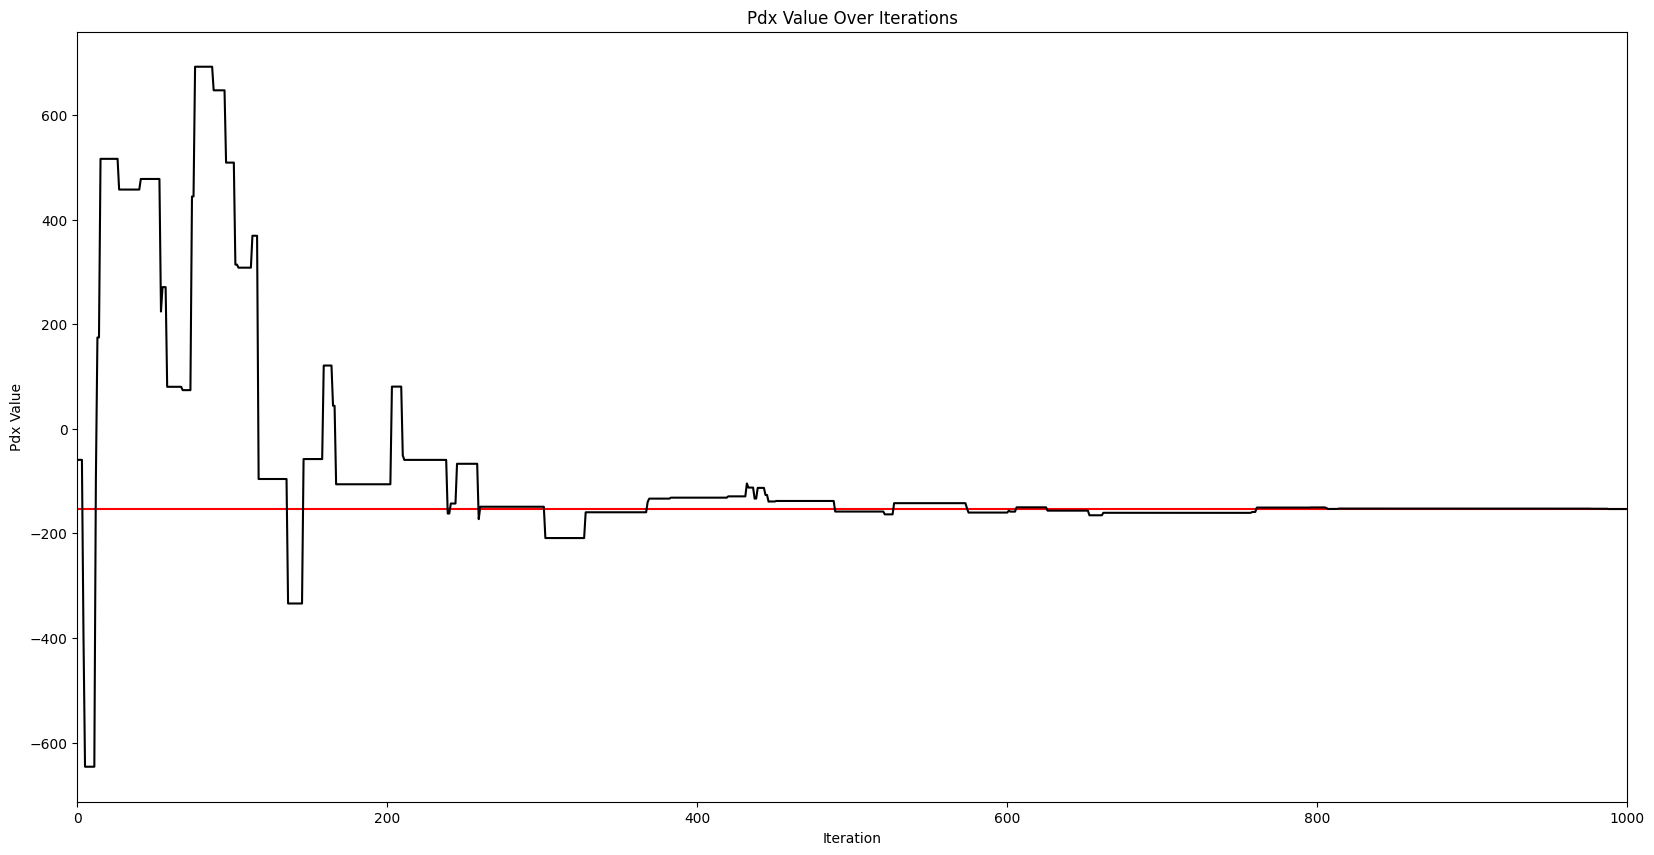

In [ ]:
plt.axhline(y=-152.75016400314658, color='r')
plt.plot(df[5], color='k')
#plt.plot(3, -2000)
plt.xlim(0,1000)
plt.title('Pdx Value Over Iterations')
plt.xlabel('Iteration')
plt.ylabel('Pdx Value')